<div align="center">
    
# ΠΑΝΕΠΙΣΤΗΜΙΟ ΚΡΗΤΗΣ
# Τμήμα Επιστήμης Υπολογιστών

## HY-215: Εφαρμοσμένα Μαθηματικά για Μηχανικούς
## Εαρινό Εξάμηνο 2025-2026
### Διδάσκοντες: Γ. Στυλιανού, Γ. Καφεντζής
    
## Ανάθεση: 7-5-2026
## Παράδοση (ηλεκτρονικά, όπως αναφέρεται στο τέλος του αρχείου): 
## Παρασκευή, 29-5-2026, 23:59:59
<h1><center>5η Σειρά Εργαστηρίου</center></h1>

Σε κάθε άσκηση `Python`, εισάγουμε πρώτα τις βιβλιοθήκες που θα χρησιμοποιήσουμε.

Επιλέξτε το παρακάτω κελί κώδικα και πατήστε Shift + Enter, ώστε να το εκτελέσετε. 

Το ίδιο θα κάνετε με οποιοδήποτε κελί κώδικα. Αν τροποποιήσετε κάποιο κελί κώδικα, θα πρέπει να το ξανατρέξετε για να δείτε τα αποτελέσματά του.

In [87]:
from scipy.signal import butter, freqz, lfilter, residue
import matplotlib.pyplot as plt
import scipy.io.wavfile as wav
import numpy as np
from scipy import signal
from IPython.display import Audio
from utils import plot_laplace_frequency_response

---
---

### 1η Άσκηση: Ο μετασχηματισμός Laplace αριθμητικά

Πλέον γνωρίζετε καλά το μετασχηματισμό Laplace και τον αντίστροφο του (δηλ. τις τεχνικές με τις οποίες μπορούμε να τον αντιστρέψουμε, καθώς δε χρησιμοποιήσαμε τον ορισμό του αντιστρόφου μετασχ. Laplace). Ας δείξουμε σε αυτήν την άσκηση ότι μπορούμε να δουλέψουμε αριθμητικά με το μετασχ. Laplace και τον αντίστροφό του, με κάπως παρόμοιο τρόπο με το μετασχ. Fourier και τον αντίστροφό του.

Ξέρετε ότι

$$X(s) = X(\sigma + j2\pi f) = \int_{-\infty}^{+\infty}x(t)e^{-st}dt = \int_{-\infty}^{+\infty}x(t)e^{-\sigma t}e^{-j2\pi ft}dt$$

Ας θεωρήσουμε το γνωστό ζεύγος

$$x(t) = e^{2t}u(t) \longleftrightarrow X(s) = \frac{1}{s-2}, \: \: \Re\{s\} = \sigma > 2$$

Ο μετασχηματισμός μπορεί να γραφεί ως

$$X(\sigma + j2\pi f) = \frac{1}{\sigma+ j2\pi f - 2} = \frac{1}{(\sigma - 2) + j2\pi f}, \: \: \sigma > 2$$

Αυτό το σήμα δεν έχει μετασχηματισμό Fourier καθώς ο φανταστικός άξονας $\sigma = 0$ δεν περιλαμβάνεται στο πεδίο σύγκλισης $\sigma > 2$. Όπως δείξαμε όμως στην πρώτη διάλεξη περί μετασχ. Laplace, "μπορούμε να το κάνουμε να έχει" 😃!

Ας ορίσουμε το σήμα

$$\hat{x}(t) = e^{2t}u(t)e^{-\sigma t} = e^{(2-\sigma)t}u(t), \: \: \sigma > 2$$

Αυτό το σήμα έχει μετασχ. Fourier

$$\hat{X}(f) = \int_{-\infty}^{+\infty}\hat{x}(t)e^{-j2\pi ft}dt = \int_{-\infty}^{+\infty}e^{(2-\sigma)t}u(t)e^{-j2\pi ft}dt = \int_{0}^{+\infty}e^{(2-\sigma)t}e^{-j2\pi ft}dt = \int_{0}^{+\infty}e^{-(\sigma-2)t}e^{-j2\pi ft}dt = \frac{1}{(\sigma-2) + j2\pi f}, \: \: \sigma > 2$$

και αντίστροφο μετασχ. Fourier

$$\hat{x}(t) = \int_{-\infty}^{+\infty}\hat{X}(f)e^{j2\pi ft}dt = \int_{-\infty}^{+\infty}\frac{1}{(\sigma-2) + j2\pi f}e^{j2\pi ft}df, \: \: \sigma > 2$$

Όμως εμάς μας νοιάζει το σήμα $x(t)$, όχι το $\hat{x}(t)$!

Μπορούμε να βρούμε το ζητούμενο σήμα πολλαπλασιάζοντας το $\hat{x}(t)$ με $e^{\sigma t}$, δηλ.

$$x(t) = \hat{x}(t)e^{\sigma t} = e^{2t}u(t)e^{-\sigma t} e^{\sigma t} = e^{2t}u(t)$$

και αντίστοιχα

$$x(t) = \hat{x}(t)e^{\sigma t} = e^{\sigma t}\int_{-\infty}^{+\infty}\frac{1}{(\sigma - 2) + j2\pi f}e^{j2\pi ft}df = \int_{-\infty}^{+\infty}\frac{e^{\sigma t}}{(\sigma - 2) + j2\pi f}e^{j2\pi ft}df, \: \: \sigma > 2$$

Ας χρησιμοποιήσουμε τα παραπάνω για να δούμε ότι πράγματι ο μετασχ. Laplace δουλεύει! Ας θέσουμε μια τιμή για το $\sigma > 2$. Έστω $\sigma = 3$. 

In [88]:
# Παράμετρος α:
a = 2

# Βήμα στο χρόνο:
dt = 0.01

# Άξονας χρόνου [-2,1] s:
t = np.arange(-2, 1 + dt, dt)

# Βήμα στη συχνότητα:
df = 0.01

# Άξονας συχνότητας [-100,100] Hz:
f = np.arange(-100, 100 + df, df)

# Σήμα (0 για t < 0, exp(at) για t > 0):
x = np.where(t <= 0, 0, np.exp(a * t))

# Επιλογή μιας τιμής του σ (έστω 3, όπως αναφέραμε):
sigma = 3

Τώρα μπορούμε να χρησιμοποιήσουμε το μετασχ. Laplace στην "ανοιχτή" μορφή του (με $s=\sigma + j2\pi f$) και να ανακατασκευάσουμε το σήμα στο χρόνο σύμφωνα με την τελευταία σχέση για το σήμα $x(t)$ που καταλήξαμε παραπάνω!

In [89]:
# Μετασχηματισμός Laplace για σ = 3:
X = 1.0 / ((sigma - a) + 1j * 2 * np.pi * f)

# Δέσμευση μνήμης:
x_est = np.zeros_like(t, dtype=complex)

# Σύνθεση του x(t) από μια "φέτα" του μετασχ. Laplace για σ=3:
for i in range(len(f)): x_est += X[i] * np.exp(sigma *t) * np.exp(1j * 2 * np.pi * f[i] * t)

# Κανονικοποίηση με df λόγω του ολοκληρώματος του x(t):
x_est = df * x_est

Ας απεικονίσουμε το αρχικό $x(t)$ και το ανακατασκευασμένο σήμα ``x_est``!

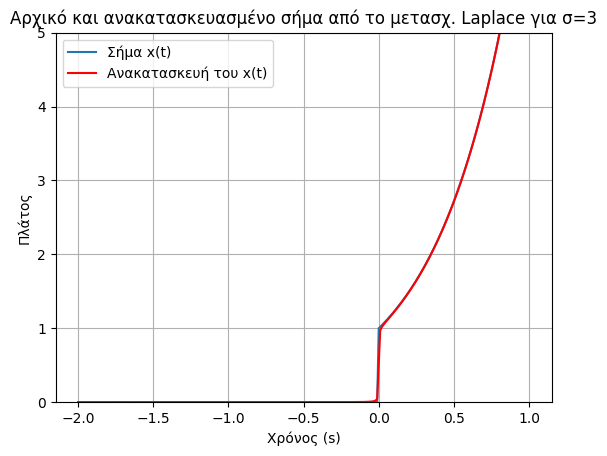

In [90]:
# Γράφημα:
plt.plot(t, x, label='Σήμα x(t)')
plt.plot(t, x_est.real, 'r', label='Ανακατασκευή του x(t)')
plt.grid()
plt.legend()
plt.ylim([0, 5])
plt.title('Αρχικό και ανακατασκευασμένο σήμα από το μετασχ. Laplace για σ=3')
plt.xlabel('Χρόνος (s)') 
plt.ylabel('Πλάτος') 
plt.show()

Βλέπετε ότι παρ' όλο που το σήμα "φεύγει" στο άπειρο όταν $t \to +\infty$, εμείς μπορέσαμε να το ανακατασκευάσουμε, απλά χρειαστήκαμε ημίτονα με αύξον (αντί σταθερό) πλάτος!

---

Γράψτε κώδικα ``Python`` για να αντιστρέψετε μέσω του μετασχ. Laplace για κάποιο κατάλληλο $\sigma$ της επιλογής σας το σήμα $x(t)$ για τα παρακάτω ζεύγη:

(α') $$x(t) = -e^{-3t}u(-t) \longleftrightarrow X(s) = \frac{1}{s+3}, \: \: \sigma < -3$$
(β') $$x(t) = e^{-2t}(t) - e^{2t}u(-t) \longleftrightarrow X(s) = \frac{2s}{(s-2)(s+2)}, \: \: -2 < \sigma < 2$$

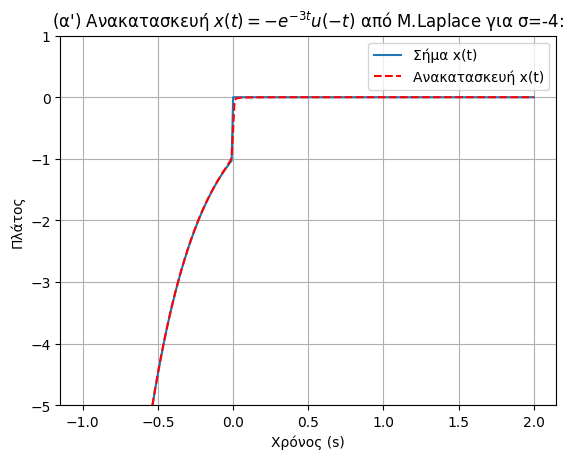

In [91]:
# (α')

a = -3
dt = 0.01
t = np.arange(-1, 2 + dt, dt)
df = 0.01
f = np.arange(-100, 100 + df, df)
x = np.where(t <= 0, -np.exp(a * t), 0)
sigma = -4

X = 1.0 / ((sigma - a) + 1j * 2 * np.pi * f)
x_est = np.zeros_like(t, dtype=complex)
for i in range(len(f)): x_est += X[i] * np.exp(sigma * t) * np.exp(1j * 2 * np.pi * f[i] * t)
x_est = df * x_est

plt.figure()
plt.plot(t, x, label='Σήμα x(t)')
plt.plot(t, x_est.real, 'r--', label='Ανακατασκευή x(t)')
plt.grid()
plt.legend()
plt.ylim([-5, 1])
plt.title('(α\') Ανακατασκευή $x(t) = -e^{-3t}u(-t)$ από M.Laplace για σ=-4:')
plt.xlabel('Χρόνος (s)')
plt.ylabel('Πλάτος')
plt.show()

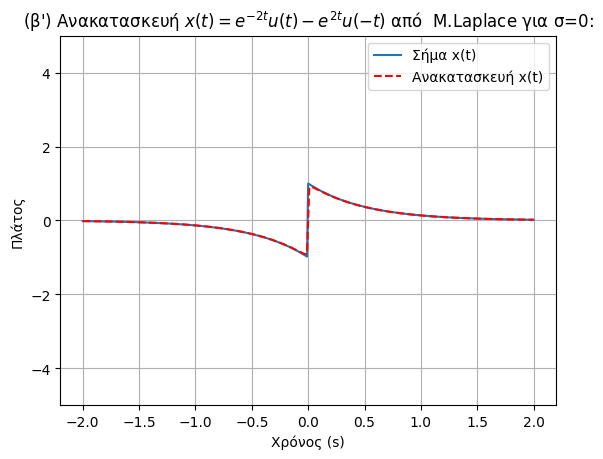

In [92]:
# (β')

dt = 0.01
t = np.arange(-2, 2 + dt, dt)
df = 0.01
f = np.arange(-100, 100 + df, df)
x = np.where(t >= 0, np.exp(-2 * t), -np.exp(2 * t))
sigma = 0

X = (2 * (sigma + 1j * 2 * np.pi * f)) / (((sigma + 1j * 2 * np.pi * f) - 2) * ((sigma + 1j * 2 * np.pi * f) + 2))
x_est = np.zeros_like(t, dtype=complex)
for i in range(len(f)): x_est += X[i] * np.exp(sigma * t) * np.exp(1j * 2 * np.pi * f[i] * t)
x_est = df * x_est

plt.figure()
plt.plot(t, x, label='Σήμα x(t)')
plt.plot(t, x_est.real, 'r--', label='Ανακατασκευή x(t)')
plt.grid()
plt.legend()
plt.ylim([-5, 5])
plt.title('(β\') Ανακατασκευή $x(t) = e^{-2t}u(t) - e^{2t}u(-t)$ από  Μ.Laplace για σ=0:')
plt.xlabel('Χρόνος (s)')
plt.ylabel('Πλάτος')
plt.show()

---
---

### 2η Άσκηση: Ανάπτυγμα σε Μερικά Κλάσματα στην Python

Έχετε ήδη καταλάβει ότι το Ανάπτυγμα σε Μερικά Κλάσματα είναι μια σωτήρια 😃 τεχνική όσον αφορά αντίστροφους μετασχηματισμούς που εκφράζονται ως **ρητή** συνάρτηση, τόσο Fourier όσο και Laplace. Φυσικά, η ``Python`` δε θα μπορούσε να μην έχει την αντίστοιχη συνάρτηση για να μας διευκολύνει, και αυτή είναι η ``residue`` της $\texttt{SciPy}$ βιβλιοθήκης. 

Έστω λοιπόν ότι έχουμε μια ρητή συνάρτηση του $j2\pi f$ ή του $s$. Η σύνταξή της εντολής για να μας κάνει το ανάπτυγμα είναι η ακόλουθη:

$$\textrm{r, p, k = residue(b, a)}$$

με 

- $\textrm{b}$ να είναι ένα διάνυσμα που περιέχει τους συντελεστές του πολυωνύμου (του $s$ ή $j2\pi f$) του **αριθμητή** σε φθίνουσα σειρά βαθμού (πρώτα ο συντελεστής του όρου με το μεγαλύτερο βαθμό, κλπ, κλπ, και τελευταία η σταθερά), και 
- $\textrm{a}$ να είναι ένα διάνυσμα που περιέχει τους συντελεστές του πολυωνύμου (του $s$ ή $j2\pi f$) του **παρονομαστή**, επίσης σε φθίνουσα σειρά βαθμού (πρώτα ο συντελεστής του όρου με το μεγαλύτερο βαθμό, κλπ, κλπ, και τελευταία η σταθερά).

Η συνάρτηση επιστρέφει τρία διανύσματα, με τα στοιχεία καθενός σε αντιστοιχία με των υπολοίπων: 
- το διάνυσμα $\textrm{r}$ περιέχει τους αριθμητές των μερικών κλασμάτων που προκύπτουν, 
- το διάνυσμα $\textrm{p}$ περιέχει τους πόλους των απλών κλασμάτων, δηλ. τις ρίζες των παρονομαστών των μερικών κλασμάτων, και 
- το διάνυσμα $\textrm{k}$ περιέχει συντελεστές όρων που προκύπτουν κατά τη διαίρεση πολυωνύμων στην περίπτωση που η ρητή συνάρτηση έχει βαθμό πολυωνύμου αριθμητή $M$ μεγαλύτερο ή ίσο με τον αντίστοιχο του παρονομαστή, $N$, δηλ. $M \geq N$.

Ας δούμε δυο παραδείγματα. 

1. Έστω:

$$X(s) = \frac{s^2 + 5s + 6}{s^3 -2s^2 - s +2}$$

Ο αριθμητής έχει συντελεστές πολυωνύμου τους $[1, 5, 6]$ και ο παρονομαστής $[1, -2, -1, 2]$ αντίστοιχα. 

Εκτελούμε λοιπόν:

In [93]:
b = [1, 5, 6]
a = [1, -2, -1, 2]
r, p, k = residue(b, a)
print(f"Αριθμητές = {r} \nΠόλοι = {p} \nΌροι συναρτήσεων δέλτα = {k}")

Αριθμητές = [-6.          0.33333333  6.66666667] 
Πόλοι = [ 1. -1.  2.] 
Όροι συναρτήσεων δέλτα = []


Από αυτό καταλαβαίνουμε αμέσως ότι επειδή το διάνυσμα $k$ είναι άδειο, δεν υπάρχουν όροι από τη διαίρεση των πολυωνύμων - λογικό κι αναμενόμενο, καθώς ο αριθμητής μας είναι δευτεροβάθμιος και ο παρονομαστής τριτοβάθμιος, δεν υπήρχε λόγος να κάνουμε διαίρεση των πολυωνύμων. 

Από τα υπόλοιπα, παρατηρούμε ότι μπορούμε να γράψουμε το αποτέλεσμα του αναπτύγματος ως

$$X(s) = \frac{s^2 + 5s + 6}{s^3 -2s^2 - s + 2} = (-6)\frac{1}{s-1} + \left(\frac{1}{3}\right)\frac{1}{s+1} + \left(\frac{20}{3}\right)\frac{1}{s-2}$$

Δυστυχώς, η ``Python`` μας αφήνει εδώ. 😃 Στη συνέχεια, ανάλογα με το πεδίο σύγκλισης, μπορούμε εμείς να γυρίσουμε τα σήματά μας πίσω στο χρόνο μέσω των γνωστών πινάκων μετασχηματισμού Laplace. 

2. Έστω:

$$X(s) = \frac{s^4 + s^3 + 3s^2 + 2s + 1}{s^3 -2s^2 -s +2}$$

Ο αριθμητής έχει συντελεστές πολυωνύμου τους $[1, 1, 3, 2, 1]$ και ο παρονομαστής $[1, -2, -1, 2]$ αντίστοιχα. Παρατηρούμε ότι ισχύει $M > N$, οπότε πρέπει να διαιρέσουμε τα πολυώνυμα πριν το Ανάπτυγμα σε Μερικά Κλάσματα. Αυτό η ``Python`` το κάνει για μας!

Εκτελούμε λοιπόν:


In [94]:
b = [1, 1, 3, 2, 1]
a = [1, -2, -1, 2]
r, p, k = residue(b, a)
print(f"Αριθμητές = {r} \nΠόλοι = {p} \nΌροι συναρτήσεων δέλτα = {k}")

Αριθμητές = [-4.          0.33333333 13.66666667] 
Πόλοι = [ 1. -1.  2.] 
Όροι συναρτήσεων δέλτα = [1. 3.]


Τώρα το διάνυσμα $k$ ΔΕΝ είναι άδειο, υπάρχουν δυο όροι από τη διαίρεση των πολυωνύμων - λογικό κι αναμενόμενο, καθώς ο αριθμητής μας είναι τεταρτοβάθμιος και ο παρονομαστής τριτοβάθμιος, οπότε πρέπει να κάνουμε διαίρεση πολυωνύμων μέχρι να "ρίξουμε" τον αριθμητή σε όρο δευτέρου βαθμού (όπου κι εκεί μπορεί πλέον να εφαρμοστεί το Ανάπτυγμα σε Μερικά Κλάσματα).

Παρατηρούμε ότι μπορούμε να γράψουμε το αποτέλεσμα του αναπτύγματος ως

$$X(s) = \frac{s^4 + s^3 + 3s^2 + 2s + 1}{s^3 -2s^2 - s + 2} = s + 3 + \left(-4\right)\frac{1}{s-1} + \left(\frac{1}{3}\right)\frac{1}{s+1} + \left(\frac{41}{3}\right)\frac{1}{s-2}$$

Γιατί όμως ονόμασα νωρίτερα το διάνυσμα $[1, 3]$, που αντιστοιχεί στους όρους $s+3$ του μετασχηματισμού, ως "όρους συναρτήσεων Δέλτα"? 

Ας υποθέσουμε ότι το σήμα μας είναι αιτατό, κι άρα θα έχει πεδίο σύγκλισης "δεξόπλευρο", όπως το $\sigma > 2$. Αν αντιστρέψουμε το μετασχηματισμό στο πεδίο του χρόνου, έχουμε

$$x(t) = \frac{d}{dt}\delta(t) + 3\delta(t) + \frac{41}{3}e^{2t}u(t) - 4e^{t}u(t) + \frac{1}{3}e^{-t}u(t)$$

Παρατηρήστε πως προέκυψαν δυο συναρτήσεις Δέλτα (μάλιστα η μια με μορφή παραγώγου της!) στο αποτέλεσμα. Δε συνηθίζεται βέβαια να έχουμε συστήματα με $M > N$, οπότε εδώ απλά χρησιμοποιήσαμε ένα τέτοιο για λόγους πληρότητας της επίδειξης της συνάρτησης ``residue``.

---

Αναπτύξτε σε μερικά κλάσματα τους παρακάτω μετασχηματισμούς:

(α') $$X(s) = \frac{24}{s(s+8)}$$
(β') $$X(s) = \frac{20}{s^2+4s+3}$$
(γ') $$X(s) = \frac{s^2}{s^2-4s+4}$$
(δ') $$X(s) = \frac{s^4 + 2s^3 + 5s + 10}{s^2 - 1}$$

### Απαντήσεις:

In [95]:
# (α') r = [ 3. -3.] , p = [ 0. -8.] , k = [] ...

b1 = [24]
a1 = [1, 8, 0]
r1, p1, k1 = residue(b1, a1)
print(f"- Αριθμητές: r = {r1} \n- Πόλοι: p = {p1} \n- Όροι συναρτήσεων δέλτα: k = {k1}")

- Αριθμητές: r = [ 3. -3.] 
- Πόλοι: p = [ 0. -8.] 
- Όροι συναρτήσεων δέλτα: k = []


In [96]:
# (β') r = [ 10. -10.] , p = [-1. -3.] , k = [] ...

b2 = [20]
a2 = [1, 4, 3]
r2, p2, k2 = residue(b2, a2)
print(f"- Αριθμητές: r = {r2} \n- Πόλοι: p = {p2} \n- Όροι συναρτήσεων δέλτα: k = {k2}")

- Αριθμητές: r = [ 10. -10.] 
- Πόλοι: p = [-1. -3.] 
- Όροι συναρτήσεων δέλτα: k = []


In [97]:
# (γ') r = [4. 4.] , p = [2. 2.] , k = [1.] ...

b3 = [1, 0, 0]
a3 = [1, -4, 4]
r3, p3, k3 = residue(b3, a3)
print(f"- Αριθμητές: r = {r3} \n- Πόλοι: p = {p3} \n- Όροι συναρτήσεων δέλτα: k = {k3}")

- Αριθμητές: r = [4. 4.] 
- Πόλοι: p = [2. 2.] 
- Όροι συναρτήσεων δέλτα: k = [1.]


In [98]:
# (δ') r = [-2.  9.] , p = [-1.  1.] , k = [1. 2. 1.] ...

b4 = [1, 2, 0, 5, 10]
a4 = [1, 0, -1]
r4, p4, k4 = residue(b4, a4)
print(f"- Αριθμητές: r = {r4} \n- Πόλοι: p = {p4} \n- Όροι συναρτήσεων δέλτα: k = {k4}")

- Αριθμητές: r = [-2.  9.] 
- Πόλοι: p = [-1.  1.] 
- Όροι συναρτήσεων δέλτα: k = [1. 2. 1.]


---
---

### 3η Άσκηση: σχεδίαση φίλτρων στο χώρο του Laplace

Εργάζεστε σε μια νεοφυή (startup) επιχείρηση ως $\textrm{μηχανικός σχεδίασης ϕίλτρων}$.

Ο προϊστάμενός σας συγκαλεί σύσκεψη στην οποία αποφασίζεται ότι εσείς πρέπει να σχεδιάσετε και να αναπτύξετε ένα ΓΧΑ σύστημα με απόκριση συχνότητας $H(f)$ για εφαρμογές επικοινωνίας ϕωνής, το οποίο θα αποκόπτει τις συχνότητες μεγαλύτερες από κάποια δοθείσα $f_c$ (η οποία λέγεται, όπως ξέρετε, συχνότητα αποκοπής - cut-off frequency) ενώ ϑα κρατά όσο γίνεται ανέπαφες τις συχνότητες μικρότερες από $f_c$. Τέτοια συστήματα γνωρίζετε ότι ονομάζονται $\textbf{ϕίλτρα επιλογής συχνοτήτων}$, και για αυτήν την άσκηση θα τα αποκαλούμε απλά ως ϕίλτρα.

Ο προϊστάμενός σας, που δε γνωρίζει θεωρία σημάτων και συστημάτων (ενώ εσείς πλέον είστε ξεφτέρια! 😃), σας παραδίδει την απόκριση συχνότητας $H(f)$ που θέλει να ϕτιάξετε, στο παρακάτω σχήμα, και σας αναφέρει ότι το ζητούμενο $f_c$ ισούται με $f_c = 3000$ Hz, αφού το ϕίλτρο θα ενσωματωθεί σε αμυντικά ασύρματα τηλεφωνικά συστήματα, όπου το εύρος ζώνης επικοινωνίας - και το κόστος λειτουργίας - είναι περιορισμένο, καθώς σημασία έχει να είναι απλά καταληπτή η επικοινωνία και όχι η ποιότητά της.

<img src="LP.png" alt="Lowpass" width="600"/>

**(α')** Γράψτε στο παρακάτω κελί (κάνοντας double click πάνω του) την εξήγηση που θα δώσετε στον προϊστάμενό σας σχετικά με το αδύνατο της πραγματοποίησης του παραπάνω φίλτρου!

### Απάντηση:

- Το ιδανικό φίλτρο δεν μπορεί να κατασκευαστεί γιατί η κρουστικη του απόκριση h(t) είναι μη μηδενική για t<0, δηλαδή είναι μη αιτιατό σύστημα. Αυτό σημαίνει ότι θα έπρεπε να γνωριζει το μέλλον και να μπορεί να απαντάει πριν καν φτάσει το σήμα εισόδου, πράγμα φυσικά αδύνατο.


**(β')** Αφού τον πείσατε για την ορθότητα του παραπάνω ερωτήματος, σας αναθέτει να υλοποιήσετε ένα φίλτρο που να πλησιάζει όσο γίνεται αυτό που σας ζήτησε αρχικά, και να είναι υλοποιήσιμο. 
Στην προσπάθειά σας αυτή, αναζητείτε μια συνάρτηση που να ταιριάζει στις "προδιαγραφές" σας. Ένας μαθηματικός φίλος σας αναφέρει ότι έχει υπόψη του μια συνάρτηση η οποία να πλησιάζει το ζητούμενο φίλτρο σας, και την οποία σχεδιάζει πρόχειρα στο χαρτί, όπως στο παρακάτω σχήμα. 

<img src="butter2.png" alt="Butterworth" width="600"/>

Η συνάρτηση ονομάζεται

### $$\text{συνάρτηση Butterworth}$$

Μη έχοντας καλύτερη εναλλακτική, του ζητάτε να σας δώσει τη μαθηματική περιγραφή της συνάρτησης. Σας δίνει μια περιγραφή στο χώρο της συχνότητας που βρήκε σε κάποιο μαθηματικό εγχειρίδιο, ως

$$\large |f(x)|^2 = \displaystyle \frac{1}{1 + \left(\frac{x}{x_c}\right)^{2N}}$$

την οποία εσείς προσαρμόζετε στις ανάγκες σας ως

$$\large |H(f)|^2 = \displaystyle \frac{1}{1 + \left(\frac{j2\pi f}{j2\pi f_c}\right)^{2N}}$$

με $N$ την **τάξη** της συνάρτησης, όπως σας ανέφερε. 

Προσέξτε ότι σας δίνει μια περίγραφή της απόκρισης πλάτους **στο τετράγωνο** (δεν ήταν και ιδιαίτερα βοηθητικός, μάλλον βαριόταν 😄)... ιδανικά θα θέλαμε τη συνάρτηση $H(f)$, ας δούμε όμως τι μπορούμε να κάνουμε.

$\LARGE \rightarrow$ Μετατρέψτε τη συνάρτηση αυτή στο χώρο του μετασχ. Laplace (βρείτε δηλ. το $|H(s)|^2$) θέτοντας $s = j2\pi f$.

**Γράψτε την απάντησή σας παρακάτω:**

### Απάντηση:

- $$\large |H(s)|^2 = \frac{1}{1 + \left(\frac{s}{j2\pi f_c}\right)^{2N}}$$

**(γ')** Θέλετε να μελετήσετε τη συμπεριφορά του φίλτρου - όπως το ονομάζετε πλέον - Butterworth, για να το κατανοήσετε καλύτερα. 

$\LARGE \rightarrow$ Βρείτε τους πόλους του $|H(s)|^2$ στο $s$-επίπεδο.

**Γράψτε την απάντησή σας παρακάτω:**

$\underline{Βοήθεια:}$
Πολλαπλασιάστε την απάντησή σας στο προηγ. ερώτημα σε αριθμητή και παρονομαστή με το $(j2\pi f_c)^{2N}$ και βρείτε τις ρίζες του παρονομαστή, χρησιμοποιώντας τη μεθοδολογία του De Moivre από την πρώτη κιόλας διάλεξη του μαθήματος. 

### Απάντηση: 

Οι πόλοι $s_k$ είναι οι $$\large s_k = j2\pi f_c \cdot e^{j\frac{(2k+1)\pi}{2N}}$$

για $k=0,1,\cdots,2N-1$.

Ας τους απεικονίσουμε για κάποια τιμή του $N$, έστω $N=8$, και $f_c=1000$ Hz, ώστε να καταλάβουμε εποπτικά τι συμβαίνει.

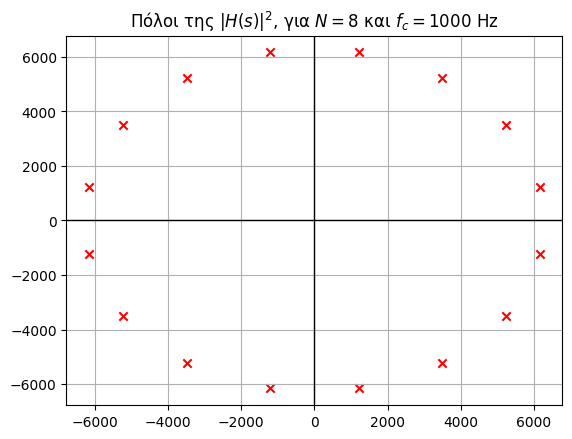

In [99]:
# Αρχικοποιούμε κάποιες μεταβλητές:
fc = 1000
N = 8
wc = 2*np.pi*fc

# Η συνάρτηση μεταφοράς |H(s)|^2 με χρήση συντελεστών των όρων της:
b = [(1j*wc)**(2*N)]
a = [1, *np.zeros(2*N - 1), (1j*wc)**(2*N)]

# Χρησιμοποιούμε την έτοιμη συνάρτηση tf2zpk του πακέτου scipy.signal:
zeros, poles, gain = signal.tf2zpk(b, a)

# Απεικονίζουμε:
plt.scatter(poles.real, poles.imag, marker='x', color='red', label='Poles')
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.title('Πόλοι της $|H(s)|^2$, για $N=8$ και $f_c=1000$ Hz')
plt.grid()                                                    
plt.show()

**(δ')** Γνωρίζετε από τη θεωρία σας ότι επειδή το φίλτρο σας έχει πραγματική κρουστική απόκριση (δηλ. $h(t) \in \mathbb{R}$), θα ισχύουν οι γνωστές συμμετρίες στο χώρο του Fourier, δηλ.

$$H(-f) = H^*(f)$$

Με χρήση αυτής, μπορούμε να γράψουμε

$$|H(f)|^2 = H(f)H^*(f) = H(f)H(-f) = H(s)H(-s)\Big|_{s=j2\pi f}$$

Άρα οι πόλοι που βρήκατε νωρίτερα στο χαρτί σας (και απεικονίσατε για κάποια τυχαία $N, f_c$) ανήκουν στο *σύνθετο* σύστημα $$|H(s)|^2 = H(s)H(-s)$$ 

Καταλαβαίνετε ότι κάποιοι πόλοι από αυτούς θα ανήκουν στο $H(s)$ και οι υπόλοιποι στο $H(-s)$, δεδομένου ότι έχουμε γινόμενο συναρτήσεων μεταφοράς. Το σύνολο των πόλων που έχετε βρει θα είναι η ένωση των συνόλων των πόλων των δυο συστημάτων, $H(s)$ και $H(-s)$.

Έχοντας βρει τους πόλους από το προηγούμενο ερώτημα, και με τη βοήθεια της απεικόνισης παραπάνω, επιλέξτε από τους πόλους που σχεδιάσατε ένα υποσύνολο πόλων που θα ανήκει στο $H(s)$, ώστε το σύστημα που θα προκύψει από αυτούς να είναι $\textbf{ευσταθές και αιτιατό}$. 

Προσέξτε ότι αν $s_p$ είναι ένας πόλος του $H(s)$, τότε ο $-s_p$ είναι $\textbf{αναγκαστικά}$ πόλος του $H(-s)$. Επίσης, ένας πόλος $s_p$ θα ανήκει είτε στο ένα σύστημα είτε στο άλλο, και όχι και στα δυο ταυτόχρονα. Τέλος, θυμηθείτε ότι $h(t) \in \mathbb{R}$, οπότε πρέπει να γνωρίζετε κάτι ακόμα για τους πόλους της συνάρτησης μεταφοράς τέτοιων σημάτων, και τον τρόπο που εμφανίζονται στο μιγαδικό επίπεδο (ως ζεύγος...... ?).

$\LARGE \rightarrow$ Ποιούς πόλους επιλέξατε από το $|H(s)|^2$ για το $H(s)$, και γιατί? Απαντήσετε παρακάτω:

**(μην περιγράψετε αριθμητικά τους πόλους - περιγράψτε τους ως προς τη θέση τους στο μιγαδικό επίπεδο)**

### Απάντηση:

- Μόνο τους πόλους που βρίσκονται στο αριστερό μιγαδικό ημιεπίπεδο, δηλαδή με αρνητικό πραγματικό μέρος.

**(ε')** Επιστρέφοντας στη θεωρία του φίλτρου Butterworth... θα χρειαστούμε τους πόλους που βρήκατε στο ερώτημα **(γ')**. Παρατηρήστε ότι

$$|H(s)|^2 \Big|_{s=0} = H(s)H(-s)\Big|_{s=0} = 1$$

και ότι

$$|H(s)|^2 = H(s)H(-s) = \frac{(j2\pi f_c)^{2N}}{\prod_{k=0}^{N-1}(s+s_k)\prod_{l=0}^{N-1}(s+s_l)}$$

με τον παρονομαστή να αφορά τους πόλους του $H(s)$ και του $H(-s)$, αντίστοιχα.

$\LARGE \rightarrow$ Υπολογίστε σε ένα πρόχειρο χαρτί το $H(s)$ για $N=1$ και $N=2$, βρίσκοντας το $|H(s)|^2$ από την παραπάνω σχέση και διαχωρίζοντας τα $H(s)$, $H(-s)$ με βάση την απαίτηση το $H(s)$ να είναι $\textbf{ευσταθές και αιτιατό}$.

$\underline{Βοήθεια:}$
Πρέπει να βρείτε: $$\displaystyle H_{N=1}(s) = \frac{2\pi f_c}{s + 2\pi f_c} , \: \: H_{N=2}(s) = \frac{(2\pi f_c)^2}{(s + 2\pi f_c e^{j3\pi/4})(s + 2\pi f_c e^{j5\pi/4})}$$

**(στ)** Εν τέλει, πώς θα υλοποιούσαμε το φίλτρο Butterworth στην πραγματικότητα? Ένας τρόπος είναι μέσω μιας διαφορικής εξίσωσης που μοντελοποιεί ένα ηλεκτρικό κύκλωμα! 

$\LARGE \rightarrow$ Βρείτε τη διαφορική εξίσωση $\textit{δευτέρας τάξης}$ (δηλ. για $N=2$) που αντιστοιχεί στο φίλτρο Butterworth που βρήκατε παραπάνω, χρησιμοποιώντας συχνότητα αποκοπής $f_c = \frac{1}{2\pi}$ Hz, και γράψτε τους συντελεστές κάθε όρου της παρακάτω:

### Απάντηση:
1. Συντελεστής του $y(t) = 1 $

2. Συντελεστής του $\frac{d}{dt}y(t) = \sqrt{2} $

3. Συντελεστής του $\frac{d^2}{dt^2}y(t) = 1 $

4. Συντελεστής του $x(t) = 1 $

**(ζ)** Υλοποιήστε στην ``Python`` την απόκριση πλάτους $|H(f)|$ του φίλτρου σας για $f_c = 3000$ Hz, δειγματοληπτώντας έναν άξονα συχνοτήτων $f$ στο διάστημα $[-5000, 5000]$ ανά $Df = 0.1$ Hz, για 
- $N=6$, 
- $N=16$,
- $N=46$. 

Για αυτό το ερώτημα, συμπληρώστε τον παρακάτω κώδικα:

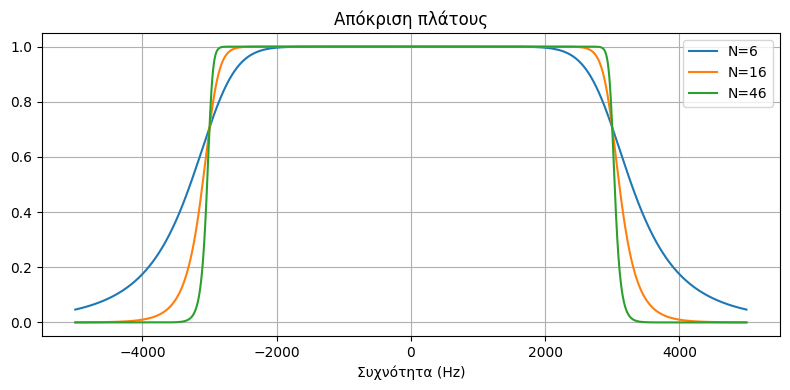

In [100]:
f = np.arange(start=-5000, stop=5000, step=0.1)
fc = 3000

N = 6
H1 = (1 / np.sqrt(1 + (f / fc) ** (2 * N)))
N = 16
H2 = (1 / np.sqrt(1 + (f / fc) ** (2 * N)))
N = 46
H3 = (1 / np.sqrt(1 + (f / fc) ** (2 * N)))

plt.figure(figsize=(8,4))

plt.plot(f, np.abs(H1))
plt.plot(f, np.abs(H2))
plt.plot(f, np.abs(H3))

plt.title('Απόκριση πλάτους')
plt.xlabel('Συχνότητα (Hz)') 
plt.grid(True)
plt.legend(['N=6', 'N=16', 'N=46']) 
plt.tight_layout()
plt.show()

**(η')** Τι παρατηρείτε στο φίλτρο σας όσο αυξάνεται η τάξη του, $N$? Γράψτε παρακάτω την απάντησή σας:

### Απάντηση:

- Τα διαγράμματα γίνονται πιο ορθογώνια και λιγότερο καμπυλοτα, δηλαδή η ζώνη μετάβασης από τη ζώνη διέλευσης στη ζώνη αποκοπής γίνεται ολοένα και πιο απότομη.

**(θ)** Προτού παραδώσετε το φίλτρο σας στον προϊστάμενό σας ώστε να υλοποιηθεί σε κύκλωμα, θέλετε να βεβαιωθείτε ότι λειτουργεί όπως πρέπει, εξομοιώνοντάς το στην ``Python`` και βάζοντας ως είσοδο μια τυπική στρατιωτική διαταγή, δωρεά του Υπουργείου Άμυνας. Θα τη βρείτε στο αρχείο ``military.wav``, στο .RAR file του εργαστηρίου.

Ακολουθήστε τα παρακάτω βήματα.

**(θ.1')** Φορτώστε το αρχείο στην Python με τη - γνωστή πια - συνάρτηση $\texttt{wav.read}$ της $\texttt{SciPy}$ και δείτε το. 

Text(0.5, 1.0, 'Σήμα στο χρόνο')

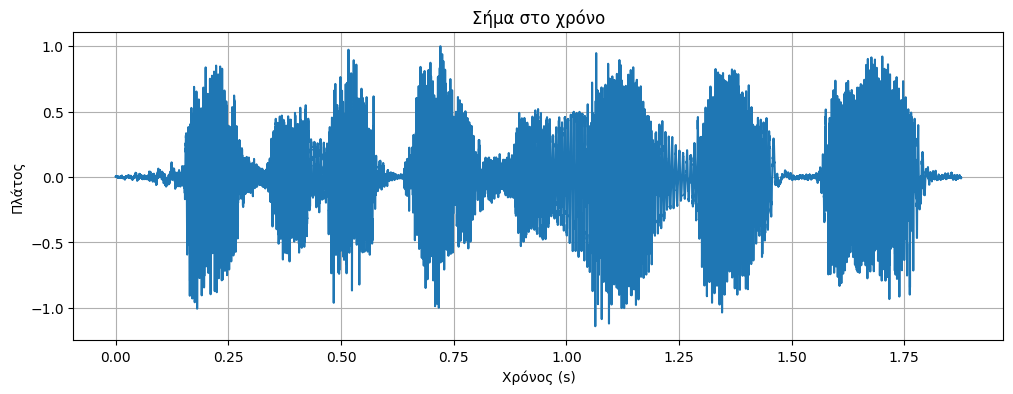

In [101]:
fs, s = wav.read('./military.wav')   # Ανάγνωση.
s = s/np.abs(np.max(s))              # Κανονικοποίηση στο [-1, 1].
t = np.arange(0, len(s)/fs, 1/fs)    # Άξονας χρόνου.

plt.figure(figsize=(12,4))           # Γράφημα.
plt.plot(t, s)                       # Περιεχόμενο.
plt.xlabel('Χρόνος (s)')             # Ομορφαίνουμε.
plt.ylabel('Πλάτος')                 # Ομορφαίνουμε.
plt.grid()                           # Ομορφαίνουμε.
plt.title('Σήμα στο χρόνο')          # Ομορφαίνουμε.

Ας το ακούσουμε:

In [102]:
Audio(s, rate=fs)

**(θ.2')** Η έτοιμη συνάρτηση ``butter`` υλοποιεί διάφορα φίλτρα Butterworth με τάξη $N$ την οποία παρέχετε εσείς ως όρισμα, όπως και τη συχνότητα αποκοπής $f_c$, και επιστρέφει τους συντελεστές του αριθμητή και του παρονομαστή για το φίλτρο σας στο χώρο του Laplace (ή και του Fourier)! 

In [103]:
fc = 3000                                                                    # Συχνότητα αποκοπής.
N = 30                                                                       # Ας επιλέξουμε τάξη ίση με 30 - ένα "αυστηρό" φίλτρο Butterworth με απότομη μετάβαση.
b, a = butter(N=N, btype='low', Wn=fc, analog=False, output='ba', fs = fs)   # Δημιουργία φίλτρου.

Παρατηρήστε ότι ζητήσαμε από τη συνάρτηση ``butter`` να μας φτιάξει ένα lowpass (χαμηλοπερατό) φίλτρο, τάξης $N$, με συχνότητα απόκοπής $W_n = f_c$, το φίλτρο μας να είναι $\textbf{ψηφιακό}$ κατευθείαν - θέτοντας $\texttt{analog=False}$ - και να μας δώσει ως έξοδο τους συντελεστές $b, a$ της συνάρτησης μεταφοράς του φίλτρου μας (που όμως, ως ψηφιακό φίλτρο, δεν ορίζεται στο χώρο του Laplace)! Το διάνυσμα των συντελεστών του αριθμητή θα είναι το $b$ ενώ του παρονομαστή θα είναι το $a$.

**(θ.3')** Δείτε την απόκριση συχνότητας $H(f)$ (μόνο για $f > 0$) του (ψηφιακού πλέον) φίλτρου σας με χρήση των εντολών:

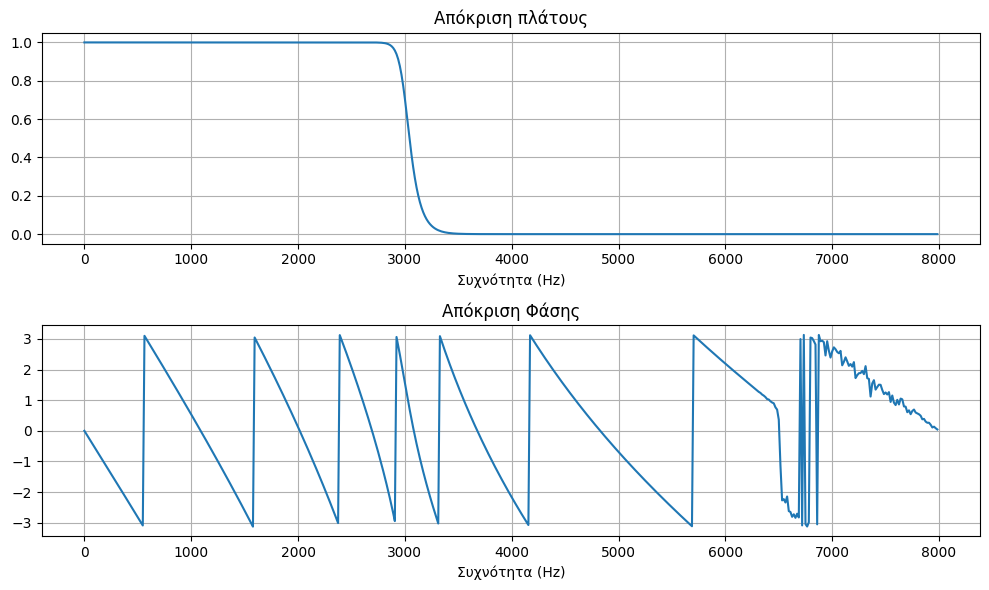

In [104]:
f, H = freqz(b=b, a=a, fs=fs)     # Καλούμε τη συνάρτηση freqz για να μας βρει την απόκριση σε συχνότητα H(f).

plt.figure(figsize=(10,6))        # Γράφημα.

plt.subplot(2, 1, 1)              # 2 γραμμές, 1 στήλη στο γράφημα: 1η γραμμή.
plt.plot(f, np.abs(H))            # Εμφάνιση απόκρισης πλάτους.
plt.title('Απόκριση πλάτους')     # Ομορφαίνουμε.
plt.xlabel('Συχνότητα (Hz)')      # Ομορφαίνουμε.
plt.grid(True)                    # Ομορφαίνουμε.

plt.subplot(2, 1, 2)              # 2 γραμμές, 1 στήλη στο γράφημα: 2η γραμμή.
plt.plot(f, np.angle(H))          # Εμφάνιση απόκρισης φάσης.
plt.title('Απόκριση Φάσης')       # Ομορφαίνουμε.
plt.xlabel('Συχνότητα (Hz)')      # Ομορφαίνουμε.
plt.grid(True)                    # Ομορφαίνουμε.

plt.tight_layout()                # Τακτοποιεί σωστά τη διάταξη των subplots.

**(θ.4')** Ας χρησιμοποιήσουμε τη συνάρτηση ``lfilter`` της βιβλιοθήκης ``SciPy`` για την υλοποίηση του συστήματος - είναι παρόμοια με την ``np.convolve`` που έχετε δει σε άλλο Εργαστήριο, απλά παίρνει διαφορετικά ορίσματα.

In [105]:
y = lfilter(b, a, x=s) # Φιλτράρισμα (ουσιαστικά, συνέλιξη στο χρόνο του φίλτρου με το σήμα εισόδου).
y = y/np.abs(np.max(y)) # Κανονικοποίηση (δεν είναι κι απαραίτητο :)).

για να φιλτράρουμε το σήμα μέσα από το σύστημα που φτιάξαμε! Ας το ακούσουμε!

In [106]:
Audio(y, rate=fs) 

Συγκρίνετε με το αρχικό:

In [107]:
Audio(s, rate=fs)

Το ίδιο και οπτικά!

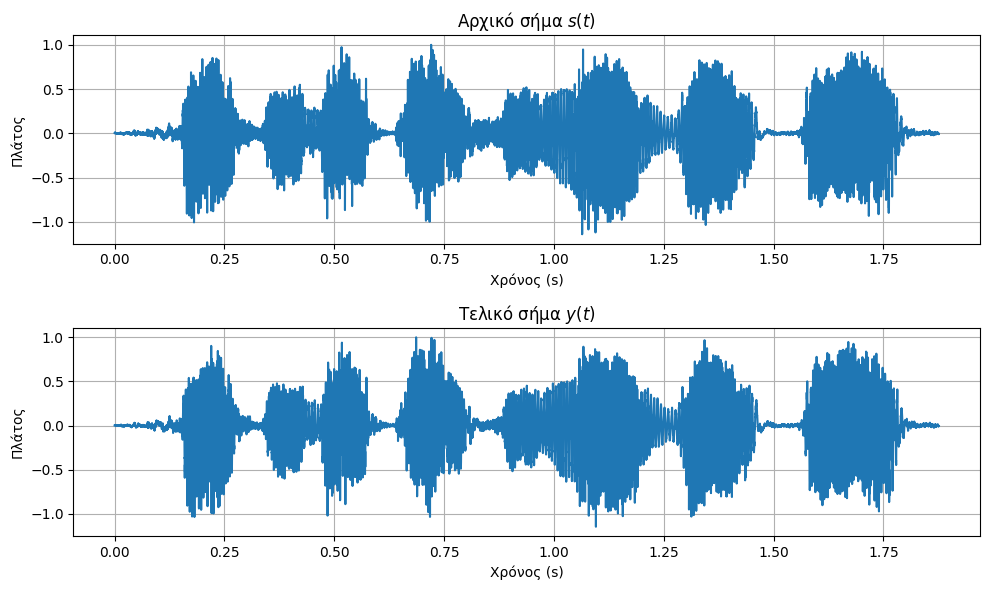

In [108]:
plt.figure(figsize=(10,6))

plt.subplot(2, 1, 1)
plt.plot(t, s)
plt.grid()
plt.title('Αρχικό σήμα $s(t)$')
plt.xlabel('Χρόνος (s)')
plt.ylabel('Πλάτος')

plt.subplot(2, 1, 2)
plt.plot(t, y)
plt.grid()
plt.title('Τελικό σήμα $y(t)$')
plt.xlabel('Χρόνος (s)')
plt.ylabel('Πλάτος')

plt.tight_layout()
plt.show()
plt.close()

Από τα σήματα στο χρόνο, ίσως να δυσκολεύεστε να καταλάβετε τη διαφορά (θα πρέπει να κάνουμε zoom σε κάποια μέρη για να δούμε περισσότερη λεπτομέρεια). 

Ας δούμε τα δυο σήματα στη συχνότητα, εκτελώντας το Μετασχηματισμό Fourier για καθένα σήμα. Επειδή όμως τα σήματα ομιλίας, μουσικής, και γενικότερα τα πραγματικά ηχητικά σήματα, αλλάζουν πολύ γρήγορα όσο περνάει ο χρόνος, προτιμάμε να εκτελούμε το μετασχ. Fourier σε **τμήματα** (segments ή frames) σήματος, όπως το έχετε ήδη δει σε προηγούμενες σειρές Εργαστηρίων. 

Αντί όμως να τυπώσουμε ένα σωρό μετασχ. Fourier (καθώς τα σήματά μας περιέχουν πάρα πολλά τμήματα), καλύτερα να:
1. Χωρίσουμε το σήμα στα προαναφερθέντα τμήματα
2. Εκτελέσουμε το μετασχ. Fourier στο καθένα
3. Υπολογίσουμε το μέτρο του (δηλ. το φάσμα πλάτους)
4. Μαζέψουμε το αποτέλεσμα σε μια μεγάλη δομή (διδιάστατο πίνακα, π.χ.)
5. Τυπώσουμε όλα μαζί τα μέτρα των μετασχ. Fourier ως μια εικόνα, με άξονες $f$ και $t$, και το χρώμα κάθε pixel στις συντεταγμένες $(t_0, f_0)$ θα μας υποδηλώνει πόσο "δυνατό" είναι το μέτρο του μετασχηματισμού σε εκείνο το σημείο.

Το τελικό αποτέλεσμα ονομάζεται **φασματογράφημα (spectrogram)**. 

**ΕΥΤΥΧΩΣ** όλα αυτά τα κάνει η συνάρτηση ``specgram`` της βιβλιοθήκης απεικονίσεων ``matplotlib`` (μεταξύ πολλών άλλων βιβλιοθηκών που έχουν παρόμοιες συναρτήσεις), και σας δίνουμε όλο το σχετικό κώδικα έτοιμο. 

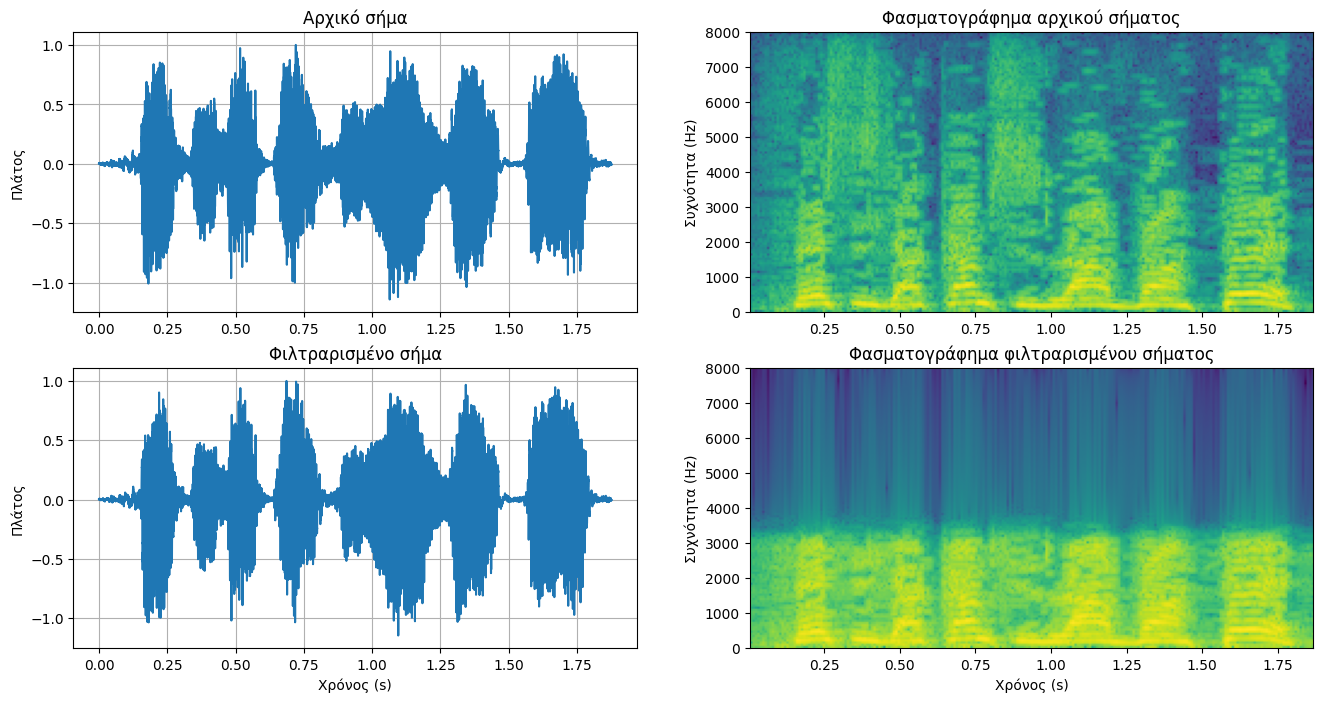

In [109]:
plt.figure(figsize=(16,8))

plt.subplot(2, 2, 1)
plt.title('Αρχικό σήμα')
plt.plot(t, s)
plt.grid()
plt.ylabel('Πλάτος')

plt.subplot(2, 2, 2)
plt.specgram(s, Fs=fs)
plt.title('Φασματογράφημα αρχικού σήματος')
plt.ylabel('Συχνότητα (Hz)')

plt.subplot(2, 2, 3)
plt.title('Φιλτραρισμένο σήμα')
plt.plot(t, y)
plt.grid()
plt.xlabel('Χρόνος (s)')
plt.ylabel('Πλάτος')

plt.subplot(2, 2, 4)
plt.specgram(y, Fs=fs)
plt.title('Φασματογράφημα φιλτραρισμένου σήματος')
plt.xlabel('Χρόνος (s)')
plt.ylabel('Συχνότητα (Hz)')
plt.show()

Τι κερδίσαμε με το παραπάνω φιλτράρισμα? Το σήμα μας πλέον έχει **εύρος ζώνης (bandwidth)** περίπου ίσο με $3000$ Hz! (αντί του αρχικού, που ήταν $8000$ Hz). Άρα για να το μεταδώσουμε μέσα από ένα κανάλι χρειαζόμαστε το $1/4$ του αρχικού εύρους ζώνης. Αυτό σημαίνει ότι πληρώνουμε μικρότερο εύρος συχνοτήτων, άρα εξοικονομούμε χρήματα, χωρίς να αλλάζει το μήνυμα που φέρει το σήμα (πιστεύω ότι καταλαβαίνετε τις λέξεις στα σήματα και στις δυο περιπτώσεις).

$\LARGE \rightarrow$ Με βάση τόσο το ακουστικό αποτέλεσμα, όσο και τα παραπάνω σχήματα, **πώς θα χαρακτηρίζατε την ποιότητα του σήματος εξόδου σε σχέση με το αρχικό**; Σκεφτείτε πως επέδρασε το φίλτρο επάνω στις συχνότητες του σήματος εισόδου. Απαντήστε παρακάτω:

### Απάντηση:

- Η ποιότητα του σήματος εξόδου ακούγεται πιο υποβαθμισμένη σε σύγκριση με το αρχικό σήμα. Αυτό είναι λογικό, αφού οι υψηλές συχνότητες (πάνω από περίπου 3000 Hz στο σχήμα), που ήταν υπεύθυνες για την καθαρότητα της φωνής, αφαιρεθηκαν. Όμως, το περιεχόμενο της ομιλίας παραμένει σε μεγάλο βαθμό κατανοητό.

---
---

### 4η Άσκηση: notch φίλτρα και "έξυπνη" αποθορυβοποίηση ήχου


Θυμηθείτε το 4ο εργαστήριο, την άσκηση με την αποθορυβοποίηση του μουσικού κομματιού "Ρόζα", των Αλκαίου/Μικρούτσικου, όπου ήταν μολυσμένο με ένα ισχυρό ημίτονο συγκεκριμένης συχνότητας που κληθήκατε να βρείτε κάνοντας συνεχείς μετασχηματισμούς Fourier πάνω στο σήμα - και με τα hints ότι το ημίτονο είχε $A = 0.01$, $\phi = 0$, και η συχνότητα που ψάχνατε ήταν ακέραιο πολλαπλάσιο των $100$ Hz στο διάστημα $[2000, 3000]$ Hz 😃!! 

Όπως είχαμε επισημάνει τότε, το παράδειγμα εκείνο ήταν πολύ εκπαιδευτικό, καθώς σας δινόταν το πλάτος, η φάση, και το "εύρος" που θα έπρεπε να ψάξετε την άγνωστη συχνότητα!

Στην πράξη, δεν μπορεί κανείς να ξέρει το πλάτος και τη φάση του ημιτονοειδούς "θορύβου", ώστε να εκτελέσει τόσο απλά την αφαίρεση $signal(t) -noise(t)$ που κάναμε τότε στο 4ο εργαστήριο, αφού είχαμε κατασκευάσει ένα "αντίγραφο" του ημιτονοειδούς θορύβου. Έτσι, χρησιμοποιούμε τα λεγόμενα **notch** φίλτρα, που αναλαμβάνουν να αποκόψουν μια πολύ πολύ μικρή μπάντα συχνοτήτων, ανεξαρτήτως πλάτους και φάσης. Τα φίλτρα αυτά ουσιαστικά μηδενίζουν το πλάτος μιας ανεπιθύμητης συχνότητας $f_{bad}$, με αποτέλεσμα η φάση να μη μας ενδιαφέρει - το γινόμενο $$0\cdot \cos(2\pi f_{bad} t + \phi)$$ ισούται με $0$, ανεξαρτήτως του $\phi$. Η απόκριση πλάτους ενός notch φίλτρου με συχνότητα αποκοπής $f_c$ φαίνεται στο παρακάτω σχήμα.

![notch](notch.png "Notch Filer")

Η σχεδίαση τέτοιων συστημάτων γίνεται κατά κανόνα στο χώρο του μετασχ. Laplace. 

Η θεωρία της κατασκευής της συνάρτησης μεταφοράς $H(s)$ ενός συστήματος notch φίλτρου είναι απλή: για παράδειγμα, αν θέλουμε να μηδενίσουμε τη συχνότητα $f_c = 5000$ Hz του σήματος που θα δεχθεί ως είσοδο το σύστημά μας, τότε:
- Μετατρέπουμε την $f_c$ σε $\omega_c = 2\pi f_c$ για ευκολία, δηλ. $\omega_c = 10000\pi$ rad/s
- Τοποθετούμε δυο **συζυγή μηδενικά** (θυμηθείτε, θέλουμε να μηδενίσουμε μια συχνότητα: όταν πολλαπλασιαστεί η απόκριση συχνότητας με το φάσμα της εισόδου, θα πρέπει το φάσμα εξόδου να έχει τιμή ΜΗΔΕΝ στις ανεπιθύμητες συχνότητες της εισόδου!) **ακριβώς πάνω στο φανταστικό άξονα** στις συχνότητες $\pm 10000\pi$, δημιουργώντας έτσι τον αριθμητή $$P(s) = (s-j\omega_c)(s+j\omega_c) = s^2 + \omega_c^2$$
- Τοποθετούμε δυο **συζυγείς πόλους** στις ίδιες συχνότητες ΑΛΛΑ όχι επάνω στο φανταστικό άξονα: ΚΟΝΤΑ του όμως, από τη μεριά του αριστερού μιγαδικού ημιεπιπέδου (γιατί?), δημιουργώντας έτσι τον παρονομαστή $$Q(s) = (s - s_1)(s - s_1^*) = s^2 + \frac{\omega_c}{Q}s + \omega_c^2$$
- Οι πόλοι ειναι της μορφής $$s_{1,1^*} = -\frac{1}{2Q}\omega_c \pm j\omega_c\sqrt{1 - \left(\frac{1}{2Q}\right)^2}$$
Ο λόγος που οι πόλοι είναι γραμμένοι έτσι δεν είναι του παρόντος 😄 αλλά η μορφή τους μας επιτρέπει, "παίζοντας" με την τιμή του $Q$, να μπορούμε να ελέγχουμε την "αυστηρότητα" του φίλτρου στη συχνότητα αποκοπής. Υψηλή τιμή του $Q$ οδηγεί σε πολύ αυστηρό - στη συχνότητα αποκοπής - φίλτρο αλλά ταυτόχρονα και πολύ "ακριβό" στην υλοποίηση.

- Έτσι, η συνάρτηση μεταφοράς μας θα είναι η 
$$H(s) = \frac{P(s)}{Q(s)} = \frac{s^2 + \omega_c^2}{s^2 + \frac{\omega_c}{Q}s + \omega_c^2}$$

Ας γράψουμε μια συνάρτηση που υλοποιεί ένα τέτοιο φίλτρο. Συμπληρώστε τον κώδικα.

In [110]:
def create_laplace_notch_filter(fc, Q):
    """
    Δημιουργία ενός notch φίλτρου και υλοποίησή του στο χώρο του Laplace.
    Παράμετροι:
    fc : Συχνότητα που πρέπει να κοπεί.
    Q : Συντελεστής ποιότητας. Όσο ψηλότερος, τόσο αυστηρότερο - και "ακριβότερο" - το φίλτρο στην αποκοπή.
    Έξοδος:
    numL, denL : Συντελεστές για αριθμητή και παρονομαστή του notch φίλτρου H(s).
    """
    # Συνήθης μορφή του φίλτρου notch: 
    # H(s) = (s^2 + ωc^2) / (s^2 + (ωc/Q)s + ωc^2)
    
    # Γωνιακή συχνότητα ωc = 2πfc rad/s:
    omegac = 2 * np.pi * fc
    
    # H(s) : αριθμητής : συντελεστές του πολυωνύμου του s ...
    num_laplace = [1, 0, omegac**2]
    
    # H(s) : παρονομαστής : συντελεστές του πολυωνύμου του s ...
    den_laplace = [1, omegac / Q, omegac**2]
    
    return num_laplace, den_laplace

Πριν συνεχίσουμε, ας δούμε γιατί η απλή τοποθέτηση δυο "σκέτων" μηδενικών επάνω στο φανταστικό άξονα, στις συχνότητες $\pm j\omega_c$ ΔΕΝ είναι αρκετή, όπως ίσως θα αναμένατε... 

Ας καλέσουμε τη συνάρτηση που φτιάξαμε, αλλά ας αγνοήσουμε τον παρονομαστή (θεωρώντας τον σταθερό πολυώνυμο, μοναδιαίο), έτσι ώστε να έχει πόλους στο άπειρο και μηδενικά στις θέσεις που θέλουμε. 

Έστω η συχνότητα $f_c = 1560$ Hz που θέλουμε να κόψουμε.

In [111]:
fc = 1560 # Hz
Q = 2
numL, denL = create_laplace_notch_filter(fc, Q) # Το κανονικό μας φίλτρο, αμέσως μετά θα αγνοήσουμε τον denL ...

Σας δίνεται έτοιμη συνάρτηση ``plot_laplace_frequency_response`` που αναλαμβάνει να απεικονίσει την απόκριση πλάτους μέσω της συνάρτησης μεταφοράς που φτιάξατε.

Γράψτε ``help(plot_laplace_frequency_response)`` για να δείτε τη σύνταξή της και μερικές λεπτομέρειες. 

In [112]:
help(plot_laplace_frequency_response)

Help on function plot_laplace_frequency_response in module utils:

plot_laplace_frequency_response(num, den, f_min=1, f_max=8000, num_points=4000)
    Εκτύπωση της απόκρισης πλάτους H(f) ενός συστήματος μέσω του μετασχ. Laplace H(s)
    
    Παράμετροι:
    ----------
    num: ndarray
        συντελεστές πολυωνύμου αριθμητή
    den: ndarray
        συντελεστές πολυωνύμου παρονομαστή
    f_min: float
        ελάχιστη συχνότητα απεικόνισης στο H(f)
    f_max: float
        μέγιστη συχνότητα απεικόνισης στο H(f)
    num_points: int
        αριθμός σημείων για τον άξονα των συχνοτήτων
        
    Επιστρέφει:
    -------
    Γράφημα




Ας την καλέσουμε.

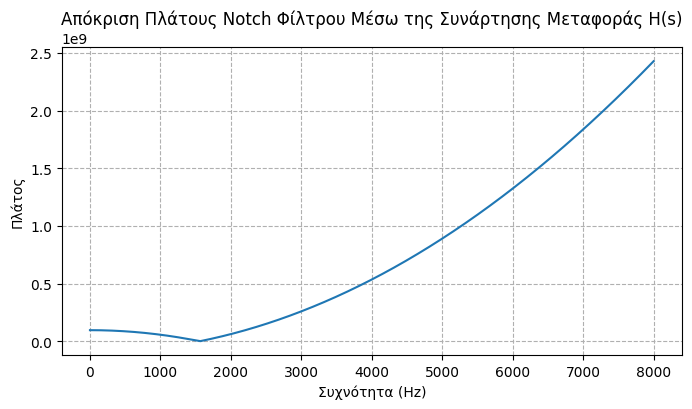

In [113]:
# Βάζουμε [1] ως παρονομαστή για να δηλώσουμε ότι το H(s) είναι πρακτικά μόνο της μορφής H(s) = P(s)/1 = (s^2 + ωc^2)/1 = s^2 + ωc^2:
plot_laplace_frequency_response(numL, [1])

Χμμ... πράγματι μηδενίζεται η ζητούμενη συχνότητα των $f_c = \pm 1560$ Hz αλλά η συμπεριφορά του φίλτρου μας δεν είναι καλή, καθώς η απόκριση πλάτους φεύγει στο άπειρο όσο μεγαλώνουν οι συχνότητες, ενισχύοντάς τες ασύλληπτα πολύ. Ταυτόχρονα, οι συχνότητες στο $[0, f_c)$ έχουν πολύ χαμηλότερο πλάτος, συγκριτικά με τις υπόλοιπες. Άρα μόνο η τοποθέτηση δυο μηδενικών στις θέσεις $s = \pm j\omega_c = \pm j2\pi f_c$ ΔΕΝ αρκεί, πράγματι. 

Αν όμως κρατήσουμε και τους πόλους? Τι γίνεται? Ας το δούμε.

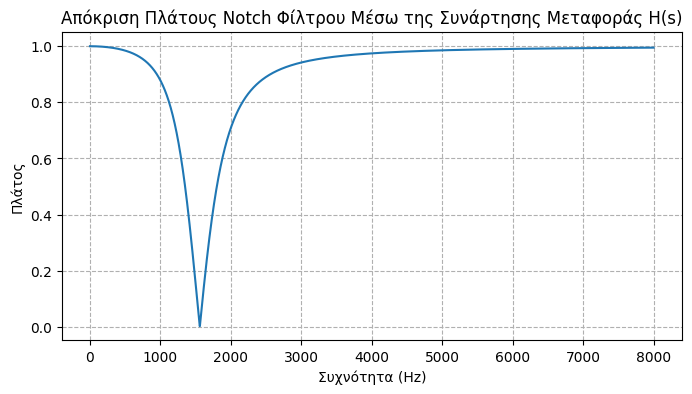

In [114]:
plot_laplace_frequency_response(numL, denL)

Ωωωωω! 😍😍 Τώρα το φίλτρο μας δουλεύει πολύ καλύτερα!! Η συχνότητα $f_c = \pm 1560$ Hz έχει απόλυτο μηδενικό πλάτος, αλλά οι γειτονικές της έχουν επίσης χαμηλότερο από μοναδιαίο πλάτος: δείτε τη συχνότητα των $\pm 2000$ Hz, το πλάτος της είναι $\approx 0.7$, αντί μοναδιαίου. Όμοια η συχνότητα των $\pm 1300$ Hz, με πλάτος $\approx 0.6$, και το ίδιο συμβαίνει και με άλλες εκεί γύρω. Αυτό δεν είναι κάτι που μας αρέσει - αν μπορούμε να το φτιάξουμε - καθώς μειώνουμε το πλάτος "χρήσιμων" συχνοτήτων, δηλ. συχνοτήτων που δε θέλουμε να πειράξουμε. Στην ουσία, το φίλτρο μας δεν είναι πολύ "αυστηρό", "κατεβαίνει απαλά και χαλαρά για να μηδενίσει τη συχνότητα $f_c$, και ανεβαίνει το ίδιο αργά και χαλαρά" - θα έλεγε κάποιος κρατώντας ένα freddo espresso στο χέρι. 😄

Πώς θα φτιάξουμε αυτό το πρόβλημα? Μα ελέγχοντας/αυξάνοντας την τιμή του $Q$ στο φίλτρο μας!

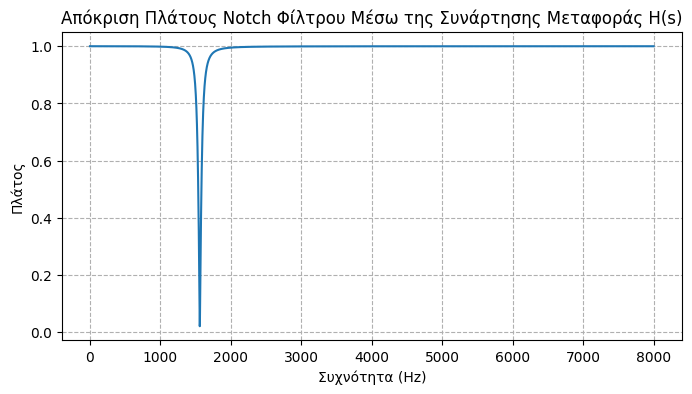

In [115]:
fc = 1560 # Hz
Q = 20
numL, denL = create_laplace_notch_filter(fc, Q)
plot_laplace_frequency_response(numL, denL)

Wow!! 😍😍 Αυτό πράγματι είναι ένα ΠΟΛΥ καλό φίλτρο! Μπορούμε καλύτερα?

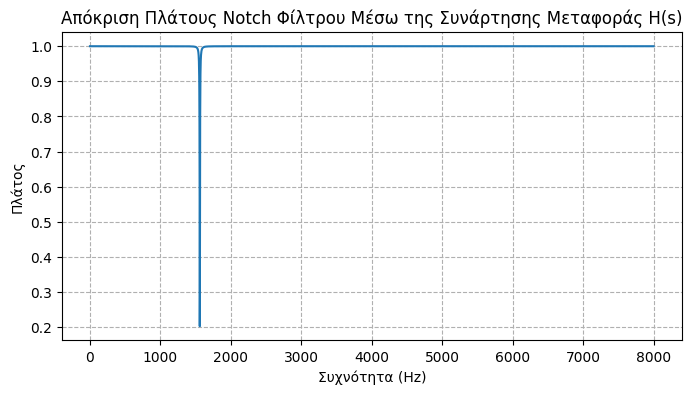

In [116]:
fc = 1560 # Hz
Q = 200
numL, denL = create_laplace_notch_filter(fc, Q)
plot_laplace_frequency_response(numL, denL)

😃😍 Αυτό είναι ένα εξαιρετικό - και πολύ απαιτητικό - φίλτρο που αποκόπτει τη συχνότητα των $1560$ Hz. 

Μη σας προβληματίζει ότι "μοιάζει" να μη μηδενίζει πλήρως τη συχνότητα $f_c$ (το σχήμα φαίνεται να σταματάει στο $0.2$ και να μην κατεβαίνει στο $0.0$), είναι ζήτημα απεικόνισης και όχι ουσίας. 

---

Ας δούμε τώρα ένα σήμα με ημιτονοειδή θόρυβο, αλλά πλέον δε θα έχετε ΚΑΜΙΑ πληροφορία για τις παραμέτρους του - πλην του ότι η συχνότητα θορύβου είναι ακέραιος αριθμός σε Hz (κι αυτό ξανά για εκπαιδευτικούς λόγους)!

In [117]:
fs, s = wav.read('BH-noise.wav')   # Φορτώστε το σήμα (BH-noise.wav, που σας δίνεται).
s = s / np.max(np.abs(s))          # Κανονικοποιήστε τα πλάτη στο [-1, 1].

Audio(s, rate=fs)                  # Ας το ακούσουμε - ΧΑΜΗΛΑ ΤΗΝ ΕΝΤΑΣΗ!.

Σε αυτήν την άσκηση, είναι προτιμότερο να μην ακολουθήσουμε το μοτίβο του 4ου εργαστηρίου, που διαλέξαμε 12 παράθυρα και είδαμε το μετασχ. Fourier και το φάσμα πλάτους τους ώστε να εντοπίσουμε την άγνωστη συχνότητα. Ας δούμε κάτι διαφορετικό. 

Ο παρακάτω κώδικας υπολογίζει το **φασματογράφημα** ενός σήματος. Όπως είπαμε και στην προηγούμενη άσκηση, αυτό δεν είναι τίποτε άλλο από μια συλλογή φασμάτων πλάτους, σε μια οπτική πιο βολική, που χρησιμοποιεί χρωματικό κώδικα για να δείξει ποιές συχνότητες είναι πιο ισχυρές από τις άλλες.

Μπορείτε να αναγνωρίσετε τη συχνότητα (ή το εύρος στο οποίο βρίσκεται) που έχει "μολύνει" το ηχητικό σήμα?

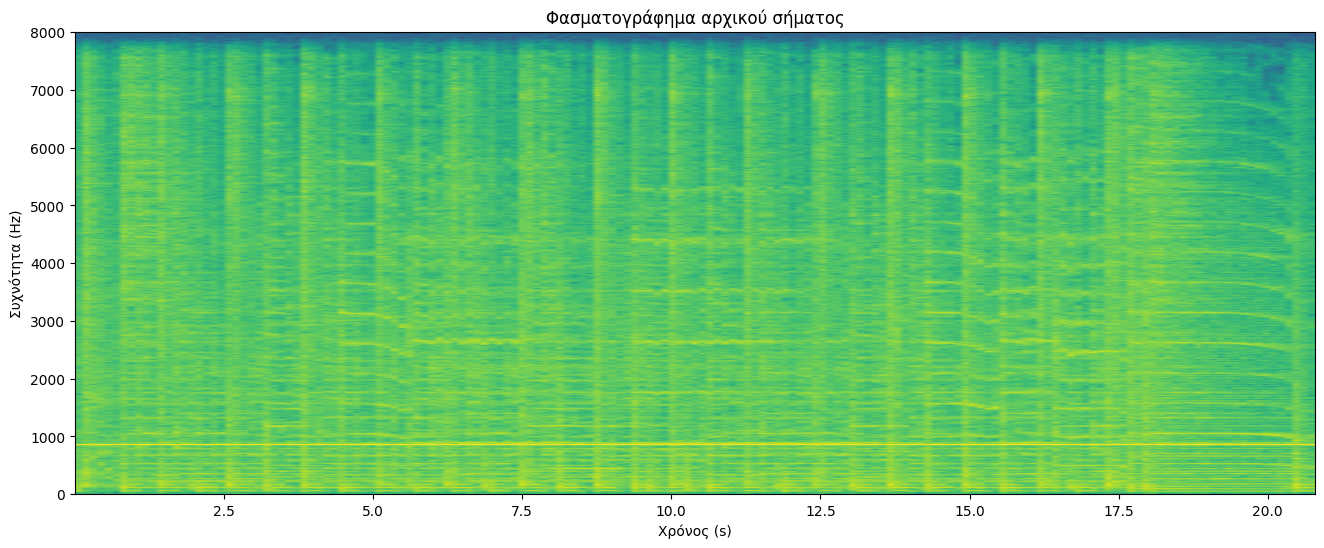

In [118]:
plt.figure(figsize=(16,6))
plt.specgram(x=s, NFFT=2048, Fs=fs, noverlap=32)
plt.title('Φασματογράφημα αρχικού σήματος')
plt.ylabel('Συχνότητα (Hz)')
plt.xlabel('Χρόνος (s)')
plt.show()

Μάλλον είναι πιο δύσκολο απ' ό,τι νομίζατε... σίγουρα αναγνωρίζετε στο σχήμα **που** πρέπει να ψάξετε - σε ποιό **εύρος συχνοτήτων** δηλαδή. 

Στον παρακάτω κώδικα, ορίστε τα όρια $f_1, f_2$ που θέλετε να ψάξετε, και ο κώδικας θα σας επιστρέψει μια "φέτα" του παραπάνω φασματογραφήματος στις συχνότητες $[f_1, f_2]$, ώστε να αναγνωρίσετε τη συχνότητα που θέλετε. 

Ίσως χρειαστεί να πειραματιστείτε 3-4 φορές στις επιλογές σας των $f_1, f_2$ μέχρι να συγκλίνετε σε κάποιο αριθμό.

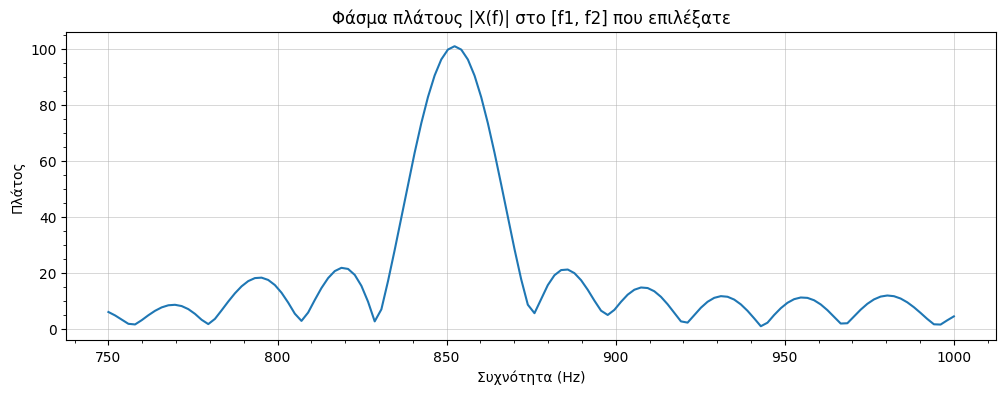

In [119]:
f1 = 750
f2 = 1000

# Πλήθος των FFT bins (μεγάλος αριθμός για να κρατήσει η ανάλυση στο zoom):
NFFT = 8192

# Fast Fourier Transform ενός τυχαίου τμήματος του σήματος:
X = np.fft.fft(s[1600:2300], NFFT)

# Ζουμάρουμε στο f = [f1, f2]:
Xzoom = X[int(2*f1/fs * NFFT/2):int(2*f2/fs * NFFT/2)]

# Άξονας συχνοτήτων f = [f1, f2]:
f = np.linspace(f1, f2, len(Xzoom))

# Απεικόνιση του φάσματος πλάτους με λεπτομέρεια:
plt.figure(figsize=(12,4))
plt.plot(f, np.abs(Xzoom))
plt.title('Φάσμα πλάτους |X(f)| στο [f1, f2] που επιλέξατε')
plt.xlabel('Συχνότητα (Hz)')
plt.ylabel('Πλάτος')
plt.grid(which='major', linestyle='-', linewidth=0.5, alpha=0.7)
plt.minorticks_on()
plt.show()

Έχετε μια καλή "μαντεψιά" για τη συχνότητα που θέλετε να κόψετε? Βάλτε την τιμή που νομίζετε παρακάτω.

In [120]:
fc = 855 #Hz

Ώρα να εφαρμόσουμε το φίλτρο μας???!!! 

Μη βιάζεστε! 😄 Το φίλτρο μας είναι "αναλογικό": είναι χτισμένο στο χώρο του Laplace, που είναι μετασχηματισμός ενός σήματος συνεχούς χρόνου. Το "μολυσμένο" σήμα που σας δίνεται είναι "ψηφιακό". Πρέπει λοιπόν να μετατρέψουμε το αναλογικό φίλτρο σε ψηφιακό. 

**ΕΥΤΥΧΩΣ** η ``Python`` φροντίζει για όλα! 

In [121]:
# Δείκτης ποιότητας φίλτρου:
Q = 200 

# Φίλτρο στο χώρο του Laplace:
# ---------------------------
# Τροποποιημένη συχνότητα fc για σωστή λειτουργία της μετατροπής από αναλογικό σε ψηφιακό (don't bother, είναι advanced υλικό):
fc_warped = (fs / np.pi) * np.tan(np.pi * fc / fs)
# Αναλογικό φίλτρο (δηλ. φίλτρο που φιλτράρει σήματα συνεχούς χρόνου):
numL, denL = create_laplace_notch_filter(fc_warped, Q)

# Φίλτρο στον "ψηφιακό" κόσμο:
# -------------------------
# Μετατροπή του αναλογικού notch φίλτρου στον "ψηφιακό" κόσμο μέσω διγραμμικού μετασχηματισμού (don't bother, είναι advanced υλικό :)):
b, a = signal.bilinear(numL, denL, fs)

# Φιλτράρισμα:
y = lfilter(b, a, s)

Ας ακούσουμε το αρχικό:

In [122]:
Audio(s, rate=fs) # Πριν τον καθαρισμό ...

Ας ακούσουμε το "καθαρό": 

In [123]:
Audio(y, rate=fs) # Μετά τον καθαρισμό ...

Τα καταφέρατε???? 😃 Αν ακούτε ακόμα το ενοχλητικό ημίτονο, δοκιμάστε μια διαφορετική συχνότητα $f_c$, και τρέξτε ξανά τα τελευταία τμήματα του κώδικα.

***
***
## Παραδοτέα:
*** 
### Μετονομάστε το **συμπληρωμένο και με εκτελεσμένο κάθε κελί κώδικα** notebook σε 

## *HY215-Lab5-2026-CSDXXXX.ipynb*, 

### με *XXXX* ο αριθμός μητρώου σας. 

### Αν είστε με προσωρινό κωδικό λόγω μεταγραφής, τότε ονομάστε το αρχείο σας 

## *HY215-Lab5-2026-mtgXXXX.ipynb*, 

### με *XXXX* ο προσωρινός αριθμός μητρώου σας.

### Αν είστε από άλλο τμήμα εκτός του CSD, τότε ονομάστε το αρχείο σας ως

## *HY215-Lab5-2026-DPTXXXX.ipynb*, 

### με DTP ένα εκ των {MATH, PHYS} και *XXXX* ο αριθμός μητρώου σας. 

### Στείλτε το μετονομασμένο notebook ως επισυναπτόμενο αρχείο με e-mail στο csd4876@csd.uoc.gr . 

### Στο e-mail θα αναγράφετε:

### - Τίτλος: [ΗΥ215] 5ο εργαστήριο Python

### και στο σώμα του e-mail τα παρακάτω: 

### - Ονοματεπώνυμο
### - ΑΜ

#### **Σημείωση**: μπορείτε να κάνετε επαναπαραδόσεις του εργαστηρίου - αν χρειαστεί. Χρησιμοποιήστε τίτλο

#### [ΗΥ215] Επαναπαράδοση 5ου εργαστηρίου Python

#### και κρατήστε τα ίδια στοιχεία στο σώμα του e-mail.

### ΠΡΟΣΕΞΤΕ: Το παραδοτέο αρχείο σας πρέπει να έχει extension .ipynb, και ΟΧΙ κάτι άλλο!!